# 일본 RSV 유행의 지역별 관계와 4주 후 보고 수 예측: 분석 코드

분석에 사용한 코드들을 하나로 정리했다. 중간보고서(`RSV_중간보고서_완성본.pdf`)의 표 2~4와 그림 1~5, 본문에 나온 수치는 모두 이 노트북에서 나온다.

`중간 보고서` 폴더에 두고 위에서부터 순서대로 실행하면 된다. 자료는 `../일본 RSV/RSV_transmission_in_Japan/`에서 읽고, numpy, pandas, scikit-learn, matplotlib이 필요하다. 대회 규정에 따라 외부 자료는 쓰지 않았다. 절 번호는 보고서의 장, 절 번호와 같게 맞췄다.

## 0. 준비

In [1]:
from pathlib import Path
from itertools import combinations
import os, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import font_manager as fm
import matplotlib.ticker as mticker
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

CANDIDATES = [Path('../일본 RSV/RSV_transmission_in_Japan'), Path('RSV_transmission_in_Japan'), Path('.')]
DATA_DIR = next((p for p in CANDIDATES if (p / 'cases.csv').exists()), None)
assert DATA_DIR is not None, 'cases.csv 못 찾음'
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
print('DATA_DIR =', DATA_DIR)

B1, B2, B3 = '#2a78d6', '#eb6834', '#1baf7a'; INK = '#0b0b0b'; INK2 = '#52514e'; MUTED = '#898781'; GRID = '#e1e0d9'; BASE = '#c3c2b7'
SEQ = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7', '#3987e5', '#2a78d6', '#256abf', '#1c5cab', '#184f95', '#104281', '#0d366b']

# 한글 폰트
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # findfont 경고가 너무 많이 떠서
_avail = {f.name for f in fm.fontManager.ttflist}
KFONT = next((f for f in ['Malgun Gothic', 'AppleGothic', 'Noto Sans CJK KR', 'NanumGothic'] if f in _avail), 'DejaVu Sans')
print('그림 글꼴:', KFONT)
plt.rcParams.update({'font.family': KFONT,
                     'font.size': 8.3, 'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 9.2,
                     'axes.titleweight': 'normal', 'axes.titlelocation': 'left', 'axes.unicode_minus': False,
                     'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.facecolor': 'white', 'legend.frameon': False, 'legend.fontsize': 7.8})

def clean(ax, ygrid=True):
    for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
    ax.tick_params(length=0)
    if ygrid: ax.yaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

def dot(ax, x, y, col, **kw):
    ax.plot(x, y, color=col, linewidth=1.3, marker='o', markersize=4.6, markeredgecolor='white', markeredgewidth=1.0, **kw)

WD = 6.7  # inch

DATA_DIR = ../일본 RSV/RSV_transmission_in_Japan
그림 글꼴: Noto Sans CJK KR


공통 함수는 한 셀에 모아 두었다. 자료 읽기, 인근 현 고르기, 예측용 표 만들기, 연도별 평가, 지표 계산, 현 단위 부트스트랩 순서다.

In [2]:
# 기상 파일 쪽 표기가 다름 (Naoasaki는 오타인 듯)
FIX = {'Hyōgo': 'Hyogo', 'Naoasaki': 'Nagasaki'}

def load(d):
    c = pd.read_csv(os.path.join(d, 'cases.csv'), index_col=0)
    pop = pd.read_csv(os.path.join(d, 'population.csv'), thousands=',')
    pop['prefecture'] = pop.prefecture.str.replace(r'-(ken|fu|to)$', '', regex=True)  # Aichi-ken -> Aichi
    W = c.pivot(index='time', columns='prefecture', values='cases').sort_index()
    yw = c.drop_duplicates('time').set_index('time')[['year', 'week']].sort_index()
    info = c.groupby('prefecture')[['lat', 'long']].first().join(pop.set_index('prefecture')[['pop', 'island']])
    info = info.loc[W.columns]
    return c, W, yw, info

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def distance_matrix(info):
    la, lo = info.lat.to_numpy(), info.long.to_numpy()
    return haversine(la[:, None], lo[:, None], la[None, :], lo[None, :])

def nearest_k(info, k=3):
    D = distance_matrix(info).copy(); np.fill_diagonal(D, np.inf)  # 자기 자신 제외
    idx = np.argsort(D, axis=1)[:, :k]
    names = info.index.to_numpy()
    return {names[i]: list(names[idx[i]]) for i in range(len(names))}

def build_panel(W, yw, info, h=4, k=3, nb_lag=0):
    # nb_lag=1이면 인근 값을 한 주 늦게 씀 (공개 지연 점검용)
    L = np.log1p(W)  # 0이 많아서 log1p
    NAT = np.log1p(W.sum(axis=1))
    nb = nearest_k(info, k)
    T = W.index.to_numpy()
    rows = []
    for p in W.columns:
        s = L[p]
        nbm = L[nb[p]].mean(axis=1).shift(nb_lag)
        df = pd.DataFrame({
            'time': T, 'pref': p, 'y_now': W[p].to_numpy(), 'y_tgt': W[p].shift(-h).to_numpy(),
            'l0': s, 'l1': s.shift(1), 'l2': s.shift(2), 'l3': s.shift(3), 'd4': s - s.shift(4),
            'nb0': nbm, 'nb_d4': nbm - nbm.shift(4), 'nb_gap': nbm - s,
            'nat0': NAT, 'nat_d4': NAT - NAT.shift(4),
        }).reset_index(drop=True)  # 이거 없으면 아래 merge에서 time이 인덱스랑 겹쳐서 에러남
        rows.append(df)
    P = pd.concat(rows, ignore_index=True)
    P = P.merge(yw.rename(columns={'year': 'o_year', 'week': 'o_week'}), left_on='time', right_index=True)
    P['t_time'] = P.time + h
    P = P.merge(yw.rename(columns={'year': 't_year', 'week': 't_week'}), left_on='t_time', right_index=True, how='left')
    # 2015, 2020년은 53주라서 52 대신 365.25/7
    P['ws'] = np.sin(2 * np.pi * P.t_week / 52.18); P['wc'] = np.cos(2 * np.pi * P.t_week / 52.18)
    P['tgt_log'] = np.log1p(P.y_tgt)
    return P

OWN = ['l0', 'l1', 'l2', 'l3', 'd4', 'ws', 'wc']
NB = ['nb0', 'nb_d4', 'nb_gap']
NAT = ['nat0', 'nat_d4']
# TODO 최종보고서: 인근 k 바꿔 보기(1~5), 같은 섬 안에서만 고르기
MODELS = {'M1 자기 현 이력': OWN, 'M2 인근 3현 추가': OWN + NB, 'M3 전국 추가': OWN + NAT, 'M4 인근과 전국 추가': OWN + NB + NAT}

def evaluate_years(P, W, yw, years=(2021, 2022, 2023), alpha=1.0):
    out = []
    for Y in years:
        y0 = yw.index[yw.year == Y].min()
        te = P[(P.o_year == Y) & (P.t_year == Y)].copy()
        # 목표 시점 기준으로 자름. 예측 시점으로 자르면 작년 마지막 4주 행의 목표값이 올해 값이 됨
        tr = P[(P.t_time < y0)].dropna(subset=OWN + NB + NAT + ['tgt_log'])
        te = te.dropna(subset=OWN + NB + NAT + ['tgt_log'])
        scale = W.loc[W.index < y0].mean().clip(lower=1.0)  # 규모 보정 MAE 분모
        te['scale'] = te.pref.map(scale)
        te['pred_M0 현재값 유지'] = te.y_now
        for name, cols in MODELS.items():
            m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(tr[cols], tr.tgt_log)
            te['pred_' + name] = np.clip(np.expm1(m.predict(te[cols])), 0, None)
        te['eval_year'] = Y
        out.append(te)
    return pd.concat(out, ignore_index=True)

def metrics(df, pcol):
    e = df[pcol] - df.y_tgt
    return pd.Series({'MAE': e.abs().mean(), 'RMSE': np.sqrt((e**2).mean()),
                      'logMAE': (np.log1p(df[pcol]) - np.log1p(df.y_tgt)).abs().mean(),
                      'scaledMAE': (e.abs() / df.scale).mean(), 'n': len(df)})

def cluster_boot_diff(df, pa, pb, B=2000, seed=0):
    # 같은 현 행끼리는 독립이 아니라서 현 단위로 뽑음. 음수면 pa가 나음
    rng = np.random.default_rng(seed)
    ea = (np.log1p(df[pa]) - np.log1p(df.y_tgt)).abs(); eb = (np.log1p(df[pb]) - np.log1p(df.y_tgt)).abs()
    g = pd.DataFrame({'p': df.pref.to_numpy(), 'a': ea.to_numpy(), 'b': eb.to_numpy()}).groupby('p').agg(['sum', 'count'])
    sa, sb, n = g[('a', 'sum')].to_numpy(), g[('b', 'sum')].to_numpy(), g[('a', 'count')].to_numpy()
    k = len(sa); idx = rng.integers(0, k, size=(B, k))
    d = sa[idx].sum(1) / n[idx].sum(1) - sb[idx].sum(1) / n[idx].sum(1)
    point = sa.sum() / n.sum() - sb.sum() / n.sum()
    return point, np.quantile(d, 0.025), np.quantile(d, 0.975)

## 1. 보이려는 것

보이려는 것은 두 가지다. 하나는 인근 현 세 곳의 보고 수를 입력에 넣으면 각 현의 4주 뒤 예측 오차가 줄어드는지이고, 다른 하나는 전국 합계를 넣은 뒤에도 그 효과가 남는지이다(보고서 1장).

## 2. 자료 (보고서 2장)

제공 자료만 쓴다. 아래 셀은 보고서 2장에 적은 수치를 확인한다. 0인 주의 비율, 현 사이 규모 차이, 기상 자료가 끝나는 주, 인근 현까지의 거리가 여기서 나온다.

In [3]:
c, W, yw, info = load(DATA_DIR)
print('보고 수:', W.shape, '| 기간:', tuple(yw.iloc[0]), '~', tuple(yw.iloc[-1]))

hum = pd.read_csv(DATA_DIR / 'humidity.csv', index_col=0)
bad = sorted(set(hum.key) - set(W.columns))
print('현 이름 불일치:', bad, '수정 후:', [FIX[k] for k in bad])
print('기상 자료 마지막 주:', hum.groupby('year').week.max().to_dict())  # 2020년 9주까지라 예측엔 못 씀

z = c.assign(period=np.select([c.year <= 2019, (c.year == 2020) | ((c.year == 2021) & (c.week <= 26))], ['2013~2019', '2020~2021년 26주'], '2021년 27주 이후'))
print('보고 수 0인 주의 비율:', z.groupby('period').cases.apply(lambda s: round((s == 0).mean(), 3)).to_dict())

mu = W.loc[yw.index[yw.year <= 2019]].mean().sort_values()
print('2013~2019 주평균 보고 수: 가장 적은 현 %s %.1f건, 가장 많은 현 %s %.1f건' % (mu.index[0], mu.iloc[0], mu.index[-1], mu.iloc[-1]))

D = distance_matrix(info); Dn = D.copy(); np.fill_diagonal(Dn, np.inf)
s3 = np.sort(Dn, axis=1)[:, :3]
nb3 = nearest_k(info)
oki = list(info.index).index('Okinawa')
print('인근 3현까지 거리 중앙값 %.0f km, 최대 %.0f km' % (np.median(s3), s3.max()))
print('오키나와의 인근 3현:', nb3['Okinawa'], '| 가장 가까운 현까지 %.0f km' % Dn[oki].min())
print('다른 섬을 잇는 인근 연결:', sum(info.island[p] != info.island[q] for p, v in nb3.items() for q in v), '/', 47 * 3)

보고 수: (574, 47) | 기간: (2013, 1) ~ (2023, 52)
현 이름 불일치: ['Hyōgo', 'Naoasaki'] 수정 후: ['Hyogo', 'Nagasaki']
기상 자료 마지막 주: {2013: 52, 2014: 52, 2015: 52, 2016: 52, 2017: 52, 2018: 52, 2019: 52, 2020: 9}
보고 수 0인 주의 비율: {'2013~2019': 0.049, '2020~2021년 26주': 0.39, '2021년 27주 이후': 0.092}
2013~2019 주평균 보고 수: 가장 적은 현 Yamanashi 9.8건, 가장 많은 현 Osaka 190.1건
인근 3현까지 거리 중앙값 81 km, 최대 757 km
오키나와의 인근 3현: ['Kagoshima', 'Miyazaki', 'Nagasaki'] | 가장 가까운 현까지 657 km
다른 섬을 잇는 인근 연결: 19 / 141


## 3. 현 사이의 동조성 (보고서 3장)

가까운 현일수록, 같은 섬에 있는 현일수록 보고 수가 비슷하게 움직였고, 코로나19 이후에는 현 사이 상관이 낮아졌다. 먼저 그림 1로 전체 흐름을 본다. 현마다 99백분위수를 1로 맞춰서 규모가 다른 현도 같은 색 범위에 들어오게 했다.

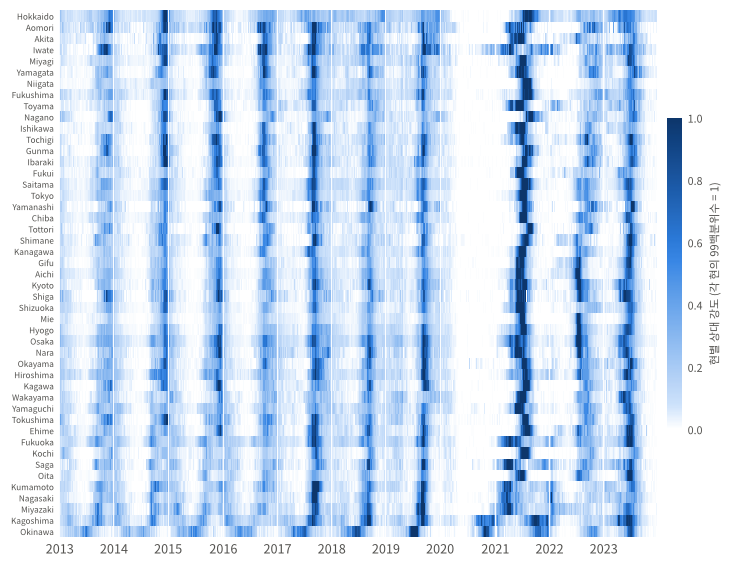

In [4]:
order = info.lat.sort_values(ascending=False).index
M = W[order].T
R = M.div(M.quantile(0.99, axis=1).replace(0, 1), axis=0).clip(upper=1.0)
yr0 = yw.reset_index().groupby('year').time.min()

fig, ax = plt.subplots(figsize=(WD, 5.2))
im = ax.imshow(R.to_numpy(), aspect='auto', cmap=LinearSegmentedColormap.from_list('seq', ['#ffffff'] + SEQ), vmin=0, vmax=1,
               interpolation='nearest', extent=[0.5, M.shape[1] + 0.5, len(order) - 0.5, -0.5])
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=5.4)
ax.set_xticks(yr0.values); ax.set_xticklabels(yr0.index.astype(str))
for sp in ax.spines.values(): sp.set_visible(False)
ax.tick_params(length=0)
for t in yr0.values: ax.axvline(t - 0.5, color='white', linewidth=0.6)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.015); cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelsize=7)
cb.set_label('현별 상대 강도 (각 현의 99백분위수 = 1)', color=INK2, fontsize=7.3)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig1_heatmap.png'); plt.show()

### 3.1 거리와 섬에 따른 상관 (그림 2)

150 km보다 가까운 쌍은 세 기간 모두 평균 상관이 0.73~0.83이었고, 800 km 넘게 떨어진 쌍은 2013~2015년에 같은 섬 0.73, 다른 섬 0.30이었다. 상관은 기간마다 현 쌍별로 log(1 + 보고 수)에서 구했다. 한 현이 여러 쌍에 들어가기 때문에 쌍을 독립 표본으로 보지는 않는다.

dbin                      <150  150–300  300–500  500–800  >800
period             same                                        
2013–2015 (겨울 유행기) False  0.83     0.80     0.69     0.63  0.30
                   True   0.83     0.81     0.81     0.78  0.73
2017–2019 (가을 유행기) False  0.78     0.76     0.69     0.63  0.38
                   True   0.79     0.73     0.71     0.68  0.67
2021–2023 (코로나 이후) False  0.73     0.57     0.46     0.52  0.37
                   True   0.74     0.63     0.65     0.62  0.58

기간별 전체 평균 상관: {'2013–2015 (겨울 유행기)': 0.682, '2017–2019 (가을 유행기)': 0.648, '2021–2023 (코로나 이후)': 0.566}


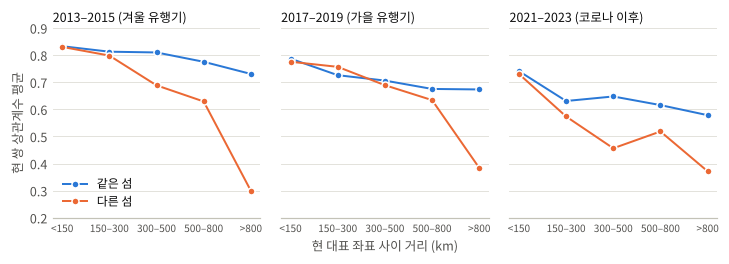

In [5]:
L = np.log1p(W); P = list(W.columns); idx = {p: i for i, p in enumerate(P)}; isl = info.island.to_dict()
# 2016(전환기), 2020(공백)은 뺌
periods = {'2013–2015 (겨울 유행기)': (2013, 2015), '2017–2019 (가을 유행기)': (2017, 2019), '2021–2023 (코로나 이후)': (2021, 2023)}
rows = []
for nm, (a, b) in periods.items():
    t = yw.index[(yw.year >= a) & (yw.year <= b)]
    Cm = np.corrcoef(L.loc[t].to_numpy().T)
    for p, q in combinations(P, 2):
        rows.append({'period': nm, 'r': Cm[idx[p], idx[q]], 'dist': D[idx[p], idx[q]], 'same': isl[p] == isl[q]})
S = pd.DataFrame(rows)
bins = ['<150', '150–300', '300–500', '500–800', '>800']
S['dbin'] = pd.cut(S.dist, [0, 150, 300, 500, 800, 3000], labels=bins)
display(S.groupby(['period', 'same', 'dbin'], observed=True).r.mean().unstack('dbin').round(2))  # same=True: 같은 섬
print('기간별 전체 평균 상관:', S.groupby('period', sort=False).r.mean().round(3).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(WD, 2.45), sharey=True)
for ax, (per, g) in zip(axes, S.groupby('period', sort=False)):
    tb = g.groupby(['same', 'dbin'], observed=True).r.mean().unstack('dbin')[bins]
    x = np.arange(len(bins))
    dot(ax, x, tb.loc[True].values, B1, label='같은 섬'); dot(ax, x, tb.loc[False].values, B2, label='다른 섬')
    clean(ax); ax.set_xticks(x); ax.set_xticklabels(bins, fontsize=6.6); ax.set_title(per, fontsize=8.2, pad=4); ax.set_ylim(0.2, 0.9)
axes[0].set_ylabel('현 쌍 상관계수 평균'); axes[1].set_xlabel('현 대표 좌표 사이 거리 (km)'); axes[0].legend(loc='lower left')
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig2_sync.png'); plt.show()

### 3.2 유행 시기를 비교하는 지표 (그림 3)

최고 주는 52주 분석 창을 어디서 시작하느냐에 따라 크게 흔들렸고, 무게중심은 거의 흔들리지 않았다. 2022년 27주에 창을 시작하면 13개 현의 최고 주가 창의 마지막 주에 걸린다. 무게중심은 보고 수를 가중치로 한 평균 주다.

,start,n_peak_last_week,Honshu_peak,Honshu_com,Kyushu_peak,Kyushu_com,Shikoku_peak,Shikoku_com
0,1,0,8.0,5.12,27.0,6.93,5.5,4.06
1,14,1,7.0,5.58,24.0,7.87,5.5,2.85
2,27,13,29.0,3.91,1.0,4.23,38.0,2.52
3,40,0,4.0,2.86,3.0,2.19,2.5,2.22


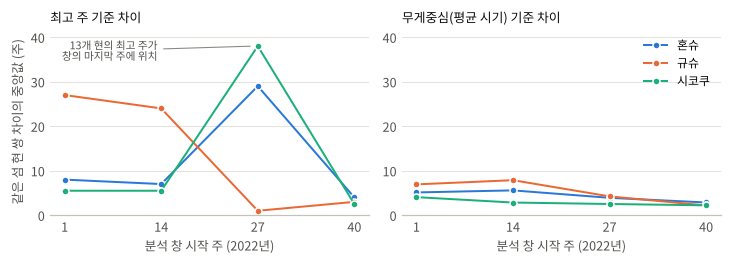

In [6]:
res = []
for s in (1, 14, 27, 40):
    t0 = yw.index[(yw.year == 2022) & (yw.week == s)][0]
    arr = W.loc[t0:t0 + 51].to_numpy()
    pk = arr.argmax(0)
    com = (arr * np.arange(52)[:, None]).sum(0) / arr.sum(0)
    out = {'start': s, 'n_peak_last_week': int((pk == 51).sum())}
    for I in ('Honshu', 'Kyushu', 'Shikoku'):  # 홋카이도, 오키나와는 현이 하나뿐
        ps = [p for p in P if isl[p] == I]
        out[f'{I}_peak'] = np.median([abs(pk[idx[x]] - pk[idx[y]]) for x, y in combinations(ps, 2)])
        out[f'{I}_com'] = round(float(np.median([abs(com[idx[x]] - com[idx[y]]) for x, y in combinations(ps, 2)])), 2)
    res.append(out)
SB = pd.DataFrame(res); display(SB)

fig, axes = plt.subplots(1, 2, figsize=(WD, 2.45))
for ax, key, ttl in [(axes[0], 'peak', '최고 주 기준 차이'), (axes[1], 'com', '무게중심(평균 시기) 기준 차이')]:
    for I, col, lab in [('Honshu', B1, '혼슈'), ('Kyushu', B2, '규슈'), ('Shikoku', B3, '시코쿠')]:
        dot(ax, SB.start, SB[f'{I}_{key}'], col, label=lab)
    clean(ax); ax.set_xticks(SB.start); ax.set_xlabel('분석 창 시작 주 (2022년)'); ax.set_title(ttl, fontsize=8.4, pad=4); ax.set_ylim(0, 42)
axes[0].set_ylabel('같은 섬 현 쌍 차이의 중앙값 (주)'); axes[1].legend(loc='upper right')
# 글자 위치는 눈으로 맞춤
axes[0].annotate('13개 현의 최고 주가\n창의 마지막 주에 위치', (26.4, 38), xytext=(13.5, 37), fontsize=7, color=INK2, ha='right', va='center',
                 arrowprops=dict(arrowstyle='-', color=MUTED, linewidth=0.7))
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig3_boundary.png'); plt.show()

## 4. 예측 방법 (보고서 4장)

다섯 모델을 같은 평가 행에서 비교한다. M1부터 M4까지는 같은 릿지 회귀(α = 1, 입력 표준화)에 입력만 바꿔 넣었다.

| 모델 | 입력 |
|---|---|
| M0 현재값 유지 | 예측 시점의 보고 수를 4주 뒤 값으로 그대로 사용(학습 없음) |
| M1 자기 현 이력 | 자기 현의 log(1 + 보고 수) 최근 4주 값, 4주 변화, 목표 주의 연중 위치(sin, cos) |
| M2 인근 3현 추가 | M1 입력, 인근 3현 평균과 그 4주 변화, 인근 평균과 자기 현의 차이 |
| M3 전국 추가 | M1 입력, 전국 합계와 그 4주 변화 |
| M4 인근과 전국 추가 | M1 입력, M2와 M3에서 더한 입력 전부 |

평가는 2021년, 2022년, 2023년을 한 해씩 따로 한다. 학습에는 목표 시점이 평가 연도 1주보다 앞선 행만 쓰기 때문에, 2022년 모델은 2021년 말까지 결과가 나온 자료로만 학습한다. 연도별 지표는 `metrics_by_year.csv`로 저장한다.

In [7]:
Pn = build_panel(W, yw, info, h=4, k=3)
E = evaluate_years(Pn, W, yw)
print('연도별 평가 행 수:', E.groupby('eval_year').size().to_dict())

names = ['M0 현재값 유지'] + list(MODELS)
rows = []
for Y in (2021, 2022, 2023):
    d = E[E.eval_year == Y]
    rows += [{'연도': str(Y), '모델': nm, **metrics(d, 'pred_' + nm).to_dict()} for nm in names]
rows += [{'연도': '전체', '모델': nm, **metrics(E, 'pred_' + nm).to_dict()} for nm in names]
T1 = pd.DataFrame(rows); T1.to_csv('metrics_by_year.csv', index=False, encoding='utf-8-sig')
display(T1.round({'MAE': 2, 'RMSE': 2, 'logMAE': 3, 'scaledMAE': 3}))

연도별 평가 행 수: {2021: 2256, 2022: 2256, 2023: 2256}


,연도,모델,MAE,RMSE,logMAE,scaledMAE,n
0,2021,M0 현재값 유지,72.26,162.57,0.917,1.766,2256.0
1,2021,M1 자기 현 이력,71.77,155.71,0.961,1.762,2256.0
2,2021,M2 인근 3현 추가,65.08,145.83,0.865,1.606,2256.0
3,2021,M3 전국 추가,71.35,156.37,0.911,1.788,2256.0
4,2021,M4 인근과 전국 추가,66.84,145.96,0.861,1.688,2256.0
5,2022,M0 현재값 유지,34.35,89.41,0.771,0.706,2256.0
6,2022,M1 자기 현 이력,29.35,81.01,0.686,0.631,2256.0
7,2022,M2 인근 3현 추가,31.31,93.62,0.668,0.672,2256.0
8,2022,M3 전국 추가,32.11,91.36,0.673,0.677,2256.0
9,2022,M4 인근과 전국 추가,32.39,94.63,0.670,0.699,2256.0


## 5. 예측 결과 (보고서 5장)

### 5.1 인근 정보는 세 해 모두 오차를 줄였다 (표 2, 그림 4)

M2의 로그 MAE는 세 해 모두 M1보다 낮았고, 세 해를 합치면 0.818에서 0.739가 되었다. 아래 표가 보고서 표 2이고, 그 아래 셀에서 차이의 95% 신뢰구간을 구한다.

In [8]:
YRS = ['2021', '2022', '2023', '전체']
T2 = T1.pivot(index='모델', columns='연도', values='logMAE').loc[names, YRS].round(3)
display(T2)

연도,2021,2022,2023,전체
모델,,,,
M0 현재값 유지,0.917,0.771,0.805,0.831
M1 자기 현 이력,0.961,0.686,0.808,0.818
M2 인근 3현 추가,0.865,0.668,0.685,0.739
M3 전국 추가,0.911,0.673,0.683,0.756
M4 인근과 전국 추가,0.861,0.670,0.662,0.731


,연도,비교,차이,하한,상한
0,2021,M2 인근 3현 추가 - M1 자기 현 이력,-0.096,-0.119,-0.071
6,2022,M2 인근 3현 추가 - M1 자기 현 이력,-0.019,-0.032,-0.006
12,2023,M2 인근 3현 추가 - M1 자기 현 이력,-0.123,-0.137,-0.109
18,전체,M2 인근 3현 추가 - M1 자기 현 이력,-0.079,-0.092,-0.066


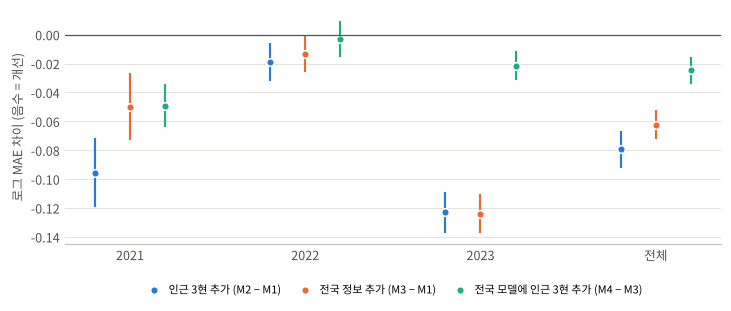

In [9]:
# 앞의 셋이 그림 4
pairs = [('M2 인근 3현 추가', 'M1 자기 현 이력'), ('M3 전국 추가', 'M1 자기 현 이력'), ('M4 인근과 전국 추가', 'M3 전국 추가'),
         ('M2 인근 3현 추가', 'M3 전국 추가'), ('M2 인근 3현 추가', 'M0 현재값 유지'), ('M1 자기 현 이력', 'M0 현재값 유지')]
cis = []
for Y in (2021, 2022, 2023, '전체'):
    d = E if Y == '전체' else E[E.eval_year == Y]
    for a, b in pairs:
        pt, lo, hi = cluster_boot_diff(d, 'pred_' + a, 'pred_' + b)
        cis.append({'연도': Y, '비교': f'{a} - {b}', '차이': pt, '하한': lo, '상한': hi})
CI = pd.DataFrame(cis)
display(CI[CI['비교'] == 'M2 인근 3현 추가 - M1 자기 현 이력'].round(3))

fig, ax = plt.subplots(figsize=(WD, 2.95))
cats = [2021, 2022, 2023, '전체']
labels = ['인근 3현 추가 (M2 − M1)', '전국 정보 추가 (M3 − M1)', '전국 모델에 인근 3현 추가 (M4 − M3)']
for j, ((a, b), lab, col) in enumerate(zip(pairs[:3], labels, [B1, B2, B3])):
    sub = CI[CI['비교'] == f'{a} - {b}']
    xs = np.arange(len(cats)) + (j - 1) * 0.2  # 겹치지 않게
    ax.vlines(xs, sub['하한'], sub['상한'], color=col, linewidth=1.4)
    ax.plot(xs, sub['차이'], 'o', color=col, markersize=5, markeredgecolor='white', markeredgewidth=1.0, label=lab, linestyle='none')
ax.axhline(0, color=INK2, linewidth=0.8); clean(ax); ax.set_xticks(range(len(cats))); ax.set_xticklabels([str(x) for x in cats])
ax.set_ylabel('로그 MAE 차이 (음수 = 개선)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=7.2, handletextpad=0.3, columnspacing=1.2)
fig.tight_layout(); fig.subplots_adjust(bottom=0.24); fig.savefig(FIG_DIR / 'fig4_effects.png'); plt.show()

### 5.2 전국 합계를 넣은 뒤에도 2021년과 2023년에는 효과가 남았다

M3에 인근 정보를 더한 M4는 2021년과 2023년에 M3보다 오차가 작았고, 2022년에는 차이가 없었다. M2와 M3를 직접 비교하면 2021년에만 M2가 나았다. 2021년 M1이 M0보다 나빴던 것도 같은 표에서 확인할 수 있다.

In [10]:
show = ['M4 인근과 전국 추가 - M3 전국 추가', 'M3 전국 추가 - M1 자기 현 이력', 'M2 인근 3현 추가 - M3 전국 추가',
        'M1 자기 현 이력 - M0 현재값 유지', 'M2 인근 3현 추가 - M0 현재값 유지']
display(CI[CI['비교'].isin(show)].sort_values(['비교', '연도'], key=lambda s: s.astype(str)).round(3))

,연도,비교,차이,하한,상한
5,2021,M1 자기 현 이력 - M0 현재값 유지,0.043,0.019,0.068
11,2022,M1 자기 현 이력 - M0 현재값 유지,-0.085,-0.107,-0.063
17,2023,M1 자기 현 이력 - M0 현재값 유지,0.003,-0.016,0.023
23,전체,M1 자기 현 이력 - M0 현재값 유지,-0.013,-0.027,0.001
4,2021,M2 인근 3현 추가 - M0 현재값 유지,-0.053,-0.086,-0.022
10,2022,M2 인근 3현 추가 - M0 현재값 유지,-0.104,-0.131,-0.076
16,2023,M2 인근 3현 추가 - M0 현재값 유지,-0.120,-0.146,-0.092
22,전체,M2 인근 3현 추가 - M0 현재값 유지,-0.092,-0.113,-0.071
3,2021,M2 인근 3현 추가 - M3 전국 추가,-0.046,-0.067,-0.024
9,2022,M2 인근 3현 추가 - M3 전국 추가,-0.005,-0.023,0.012


### 5.3 2022년에는 원래 단위의 큰 오차가 커졌다 (표 3, 그림 5)

2022년 M2는 로그 MAE가 M1보다 낮은데도 원래 단위의 MAE와 RMSE가 더 컸다. 늘어난 제곱 오차의 82%가 오사카, 아이치, 효고에서 나왔고, 대부분 정점 직후를 예측한 행이었다. 아래 첫 표가 보고서 표 3이다.

In [11]:
T3 = T1.pivot(index='모델', columns='연도', values=['MAE', 'RMSE']).swaplevel(axis=1)
T3 = T3[[(y, k) for y in YRS for k in ('MAE', 'RMSE')]].loc[names].round(1)
display(T3)
print('2022년 규모 보정 MAE: M1 %.3f, M2 %.3f' % tuple(T1[(T1['연도'] == '2022') & T1['모델'].isin(['M1 자기 현 이력', 'M2 인근 3현 추가'])].scaledMAE))

연도            2021         2022        2023          전체       
               MAE   RMSE   MAE  RMSE   MAE  RMSE   MAE   RMSE
모델                                                            
M0 현재값 유지     72.3  162.6  34.3  89.4  40.8  77.4  49.1  116.1
M1 자기 현 이력    71.8  155.7  29.3  81.0  38.0  73.5  46.4  109.9
M2 인근 3현 추가   65.1  145.8  31.3  93.6  33.1  66.4  43.2  107.1
M3 전국 추가      71.3  156.4  32.1  91.4  34.4  68.4  45.9  111.8
M4 인근과 전국 추가  66.8  146.0  32.4  94.6  33.1  66.3  44.1  107.5

2022년 규모 보정 MAE: M1 0.631, M2 0.672


제곱 오차 증가분 중 상위 3개 현의 비중: 0.82 {'Osaka': 2610664.0, 'Aichi': 1004666.0, 'Hyogo': 474152.0}


,pref,o_week,t_week,y_now,y_tgt,pred_M1 자기 현 이력,pred_M2 인근 3현 추가
3820,Osaka,29,33.0,1428,526.0,1225.6,1861.9
3819,Osaka,28,32.0,1280,688.0,1134.1,1820.5
3821,Osaka,30,34.0,1253,454.0,942.1,1369.7
2283,Aichi,28,32.0,1097,307.0,857.8,1203.1
2284,Aichi,29,33.0,916,162.0,744.6,997.7
2859,Hyogo,28,32.0,675,439.0,708.1,1063.8
2285,Aichi,30,34.0,769,84.0,533.8,773.1
2860,Hyogo,29,33.0,694,344.0,866.0,1064.1


2022년 정점 주: {'Aichi': 28, 'Osaka': 29, 'Hyogo': 30}


,o_week,t_week,y_now,y_tgt,pred_M1 자기 현 이력,pred_M2 인근 3현 추가
3820,29,33.0,1428,526.0,1226.0,1862.0


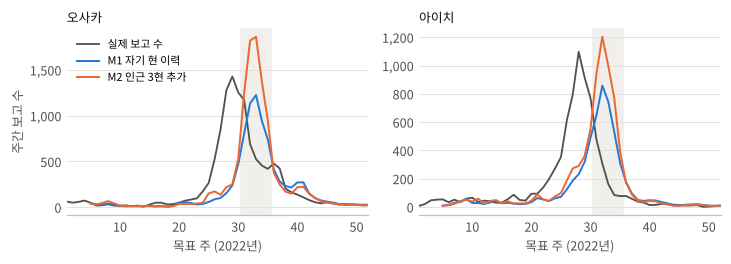

In [12]:
d = E[E.eval_year == 2022].copy()
a, b = 'pred_M2 인근 3현 추가', 'pred_M1 자기 현 이력'
d['dSE'] = (d[a] - d.y_tgt)**2 - (d[b] - d.y_tgt)**2  # +면 M2가 더 틀림
bp = d.groupby('pref').dSE.sum().sort_values(ascending=False)
print('제곱 오차 증가분 중 상위 3개 현의 비중: %.2f' % (bp.head(3).sum() / d.dSE.sum()), bp.head(3).round(0).to_dict())
display(d.sort_values('dSE', ascending=False).head(8)[['pref', 'o_week', 't_week', 'y_now', 'y_tgt', b, a]].round(1))

peak = {p: int(yw.loc[W[p].loc[yw.index[yw.year == 2022]].idxmax(), 'week']) for p in ['Aichi', 'Osaka', 'Hyogo']}
print('2022년 정점 주:', peak)
# 본문 오사카 예시 (29주에 33주 예측)
display(d[(d.pref == 'Osaka') & (d.o_week == 29)][['o_week', 't_week', 'y_now', 'y_tgt', b, a]].round(0))

fig, axes = plt.subplots(1, 2, figsize=(WD, 2.45))
for ax, p, nm in [(axes[0], 'Osaka', '오사카'), (axes[1], 'Aichi', '아이치')]:
    g = d[d.pref == p].sort_values('t_week'); obs = W[p].loc[yw.index[yw.year == 2022]]
    ax.plot(np.arange(1, len(obs) + 1), obs.values, color=INK2, linewidth=1.2, label='실제 보고 수')
    ax.plot(g.t_week, g[b], color=B1, linewidth=1.3, label='M1 자기 현 이력'); ax.plot(g.t_week, g[a], color=B2, linewidth=1.3, label='M2 인근 3현 추가')
    ax.axvspan(30.5, 35.5, color='#f0efec', zorder=0)  # 31~35주
    clean(ax); ax.set_xlim(1, 52); ax.set_xlabel('목표 주 (2022년)'); ax.set_title(nm, fontsize=8.4, pad=4)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, q: f'{int(v):,}'))
axes[0].set_ylabel('주간 보고 수'); axes[0].legend(loc='upper left', fontsize=7.2)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig5_2022_examples.png'); plt.show()

### 5.4 인근 정보는 보고 수가 크게 변하는 단계에서 도움이 되었다 (표 4)

목표 시점 보고 수가 예측 시점보다 20% 넘게 많으면 상승, 20% 넘게 적으면 하강, 그 밖은 정체로 나눴다. 실제 결과를 보고 나누는 사후 진단이라 모델 입력에는 넣지 않는다. 상승 단계에서는 세 해 모두 M2가 나았고, 정체 단계에서는 세 해 모두 M2가 더 나빴다.

In [13]:
a, b = 'pred_M2 인근 3현 추가', 'pred_M1 자기 현 이력'
# 20%는 그냥 정한 기준. TODO 15%, 25%로도 확인
E['phase'] = np.where(E.y_tgt > E.y_now * 1.2, '상승', np.where(E.y_tgt < E.y_now / 1.2, '하강', '정체'))
lm = lambda x, col: (np.log1p(x[col]) - np.log1p(x.y_tgt)).abs().mean()
rows4 = []
for ph in ['상승', '하강', '정체']:
    for Y in (2021, 2022, 2023):
        x = E[(E.phase == ph) & (E.eval_year == Y)]
        rows4.append({'단계': ph, '연도': Y, '행 수': len(x), 'M1': round(lm(x, b), 3), 'M2': round(lm(x, a), 3)})
T4 = pd.DataFrame(rows4).set_index(['단계', '연도']).unstack('연도').swaplevel(axis=1)
T4 = T4[[(Y, k) for Y in (2021, 2022, 2023) for k in ('행 수', 'M1', 'M2')]].loc[['상승', '하강', '정체']]
display(T4)

연도 2021               2022                2023              
    행 수     M1     M2  행 수     M1     M2   행 수     M1     M2
단계                                                          
상승  954  1.203  1.065  893  0.855  0.787   862  0.962  0.837
하강  855  1.075  0.930  944  0.688  0.677  1077  0.843  0.683
정체  447  0.225  0.313  419  0.324  0.393   317  0.268  0.277

### 5.5 인근 보고가 1주 늦게 들어와도 개선의 대부분이 남았다

인근 현 값을 한 주 전 것으로 바꿔서 다시 평가했다. 일본 감시 자료가 실제로 얼마나 늦게 공개되는지는 아직 확인하지 못했다.

In [14]:
E1 = evaluate_years(build_panel(W, yw, info, h=4, k=3, nb_lag=1), W, yw)  # TODO 2주 지연도
own = metrics(E, 'pred_M1 자기 현 이력').logMAE
same = metrics(E, 'pred_M2 인근 3현 추가').logMAE
lag1 = metrics(E1, 'pred_M2 인근 3현 추가').logMAE
print(f'세 해 전체 로그 MAE: M1 {own:.3f} | M2 같은 주 {same:.3f} | M2 1주 지연 {lag1:.3f} | 개선분 유지율 {(own - lag1) / (own - same):.0%}')

세 해 전체 로그 MAE: M1 0.818 | M2 같은 주 0.739 | M2 1주 지연 0.748 | 개선분 유지율 88%


## 정리

연도별 지표는 `metrics_by_year.csv`에, 그림 1~5는 `figures/` 폴더에 저장된다. 모델 구성과 평가 방식은 최종보고서까지 그대로 두고, 새로 하는 분석은 이 뒤에 절을 붙여 이어 갈 생각이다.